# Week 2 — Blackjack Probability Engine
**IEMS 302 consolidation project**

**The plan:** answer probability questions two ways — *exact counting* and
*simulation* — and confirm they agree. Easy questions (where we can check the
math) build trust in simulation, which Week 3 needs when the math gets too hard.

We use `blackjack.py` for the heavy lifting and derive the key formulas by hand
below. Run top to bottom.

## 0. Setup

In [2]:
import sys, pathlib

# blackjack.py lives one directory up from this notebook
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import math
import numpy as np
import blackjack as bj
from IPython.display import Image, display

## 1. P(blackjack) — derived by hand (combinatorics)

A blackjack is **one Ace + one ten-value card** (10, J, Q, K) in the first two
cards. Counting:

- Total distinct 2-card hands: $\binom{52}{2} = 1326$.
- Aces available: $4$.  Ten-value cards: $4 \text{ ranks} \times 4 \text{ suits} = 16$.
- Favourable hands: $\binom{4}{1}\binom{16}{1} = 4 \times 16 = 64$.

$$P(\text{blackjack}) = \frac{64}{1326} = 0.04827\ldots \approx 4.83\%$$

In [3]:
favourable = math.comb(4,1)*math.comb(16,1)
print("favourable hands:", favourable, " total hands:", math.comb(52,2))
print("P(blackjack) =", bj.p_blackjack_exact())

favourable hands: 64  total hands: 1326
P(blackjack) = 0.048265460030165915


## 2. P(pair) — derived by hand (combinatorics)

A pair = both cards share a rank. For each of the 13 ranks, the number of ways
to choose 2 of its 4 suits is $\binom{4}{2}=6$.

$$P(\text{pair}) = \frac{13 \times \binom{4}{2}}{\binom{52}{2}}
                 = \frac{13 \times 6}{1326} = \frac{78}{1326} \approx 5.88\%$$

In [4]:
print("P(pair) =", bj.p_pair_exact())

P(pair) = 0.058823529411764705


## 3. P(dealer busts | upcard) — conditional probability (recursion)

This one has no one-line formula, so we use the **Law of Total Probability**
over the dealer's next card. Model (standard simplification): infinite deck, so
each draw is independent with $P(\text{rank})=\tfrac{1}{13}$ and ten-value cards
$P=\tfrac{4}{13}$. Dealer hits below 17, stands on 17+ (S17).

Let $B(h)$ = P(dealer busts | current hand $h$). Then

$$B(h) = \sum_{\text{card } c} P(c)\, B(h \cup c),
\qquad B(h)=\begin{cases}1 & \text{total}>21\\ 0 & \text{total}\ge 17\end{cases}$$

`blackjack.py` implements exactly this recursion (with proper Ace handling).

In [5]:
upcards = list(range(2,11)) + [11]   # 2..10, then Ace
for u in upcards:
    label = "A" if u==11 else u
    print(f"upcard {label:>2}:  P(bust) = {bj.p_dealer_bust_exact(u):.4f}")

upcard  2:  P(bust) = 0.3536
upcard  3:  P(bust) = 0.3739
upcard  4:  P(bust) = 0.3945
upcard  5:  P(bust) = 0.4164
upcard  6:  P(bust) = 0.4232
upcard  7:  P(bust) = 0.2623
upcard  8:  P(bust) = 0.2447
upcard  9:  P(bust) = 0.2284
upcard 10:  P(bust) = 0.2121
upcard  A:  P(bust) = 0.1153


The dealer is most likely to bust showing a **6** (~42%) and least likely
showing an **Ace** (~12%). That single fact is the backbone of basic strategy:
press your bets when the dealer shows a weak card.

## 4. Validate by simulation (Law of Large Numbers)
Now deal a million random hands and confirm the experiment matches the math.
`blackjack.main()` runs everything and writes plots to `results/`.

In [6]:
bj.main()

P(blackjack):  exact 0.0483 (64/1326)  |  simulated 0.0481
P(pair):       exact 0.0588 (78/1326)  |  simulated 0.0592

Dealer bust probability (S17, infinite deck):
   upcard  analytic      sim
        2    0.3536   0.3543
        3    0.3739   0.3737
        4    0.3945   0.3942
        5    0.4164   0.4168
        6    0.4232   0.4233
        7    0.2623   0.2625
        8    0.2447   0.2433
        9    0.2284   0.2279
       10    0.2121   0.2119
        A    0.1153   0.1151

Decision analysis — EV of standing vs hitting (win=+1, lose=-1):
  player 16 vs dealer 10:  stand -0.576  hit -0.569  ->  HIT
  player 12 vs dealer 4:  stand -0.211  hit -0.214  ->  STAND
  player 13 vs dealer 6:  stand -0.154  hit -0.236  ->  STAND
  player 15 vs dealer 7:  stand -0.475  hit -0.374  ->  HIT

Plots + table written to: /Users/theonestendahimana/Desktop/summer_26_proj/quant-summer-2026/projects/02-blackjack-probability/results


### The convergence picture
Estimates swing wildly with few trials, then lock onto the exact value — that
settling-down *is* the Law of Large Numbers, and it's why we can trust
simulation once the trial count is large.

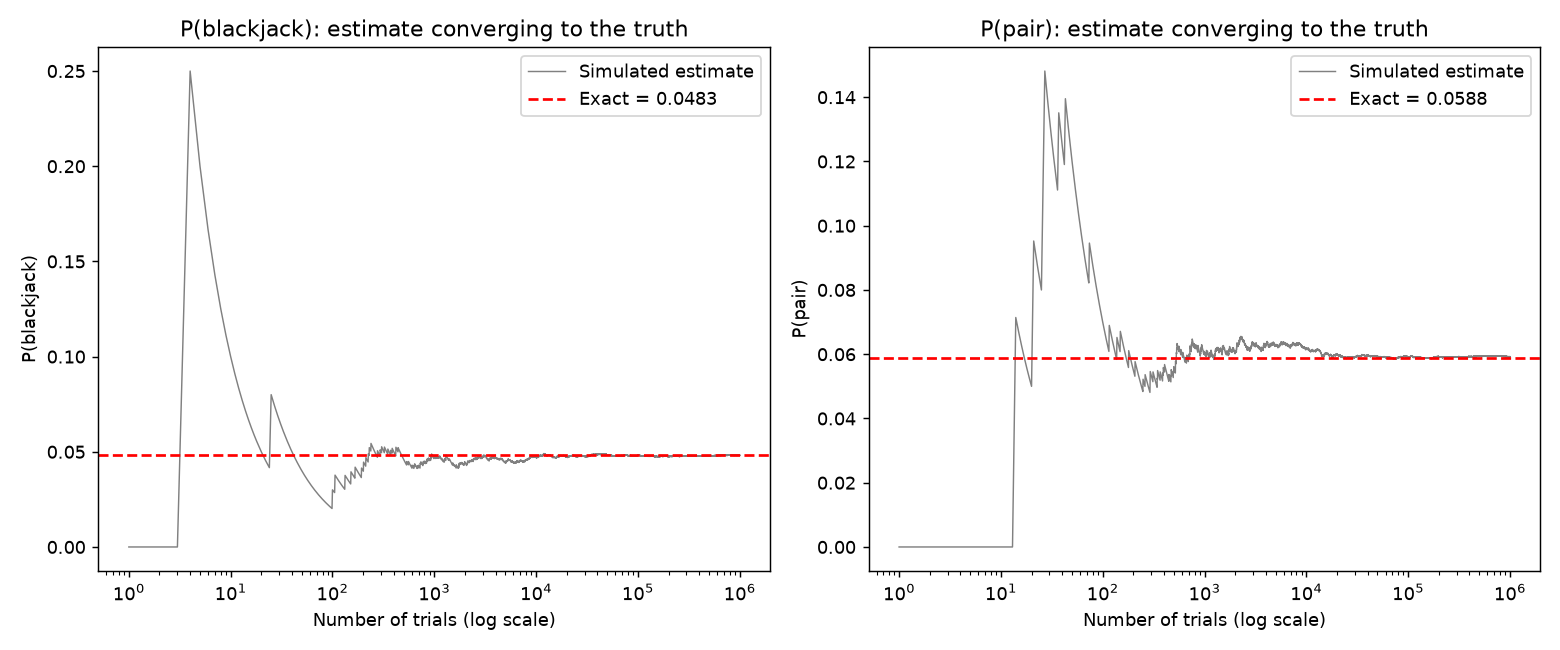

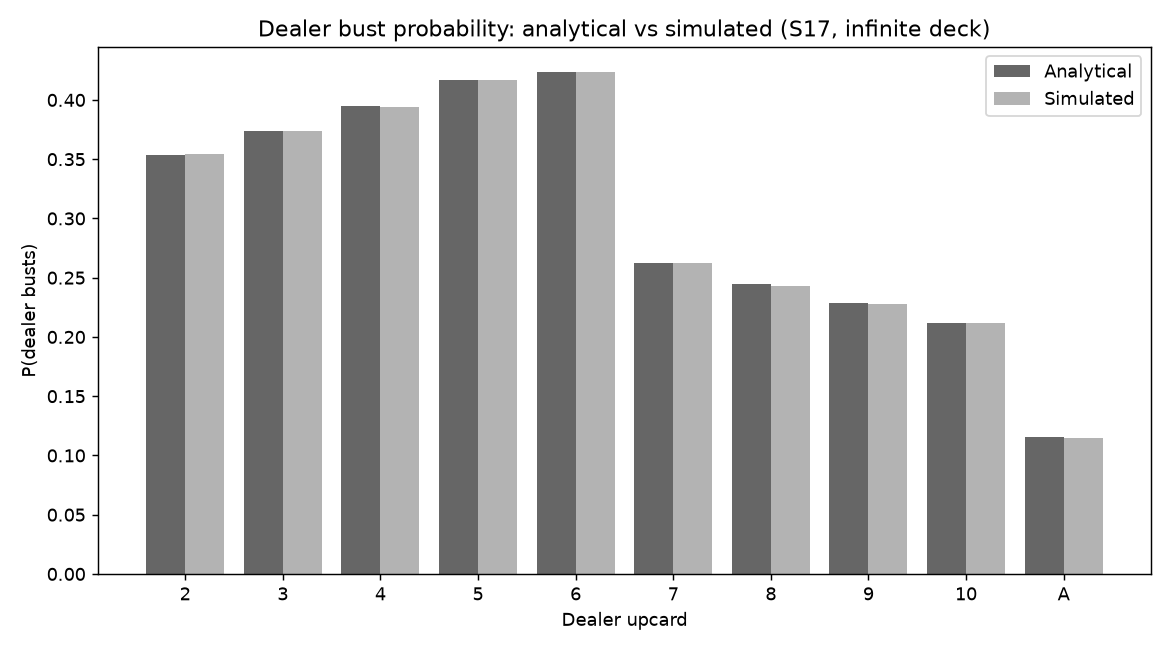

In [7]:
results_dir = str(pathlib.Path.cwd().parent / "results")
display(Image(f"{results_dir}/convergence.png"))
display(Image(f"{results_dir}/dealer_bust.png"))

## 5. Bonus — using probability to make a DECISION
A sneak peek at Weeks 9-10. For a player total vs a dealer upcard, compare the
expected value (win=+1, lose=-1, push=0) of **standing** vs **taking one card**.

In [8]:
for total, up in [(16,10),(12,4),(13,6),(15,7),(11,6),(17,9)]:
    es, eh = bj.ev_stand(total, up), bj.ev_hit_then_stand(total, up)
    print(f"player {total:>2} vs dealer {('A' if up==11 else up)}:  "
          f"stand {es:+.3f} | hit {eh:+.3f}  ->  {bj.best_action(total, up)}")

player 16 vs dealer 10:  stand -0.576 | hit -0.569  ->  HIT
player 12 vs dealer 4:  stand -0.211 | hit -0.214  ->  STAND
player 13 vs dealer 6:  stand -0.154 | hit -0.236  ->  STAND
player 15 vs dealer 7:  stand -0.475 | hit -0.374  ->  HIT
player 11 vs dealer 6:  stand -0.154 | hit +0.334  ->  HIT
player 17 vs dealer 9:  stand -0.423 | hit -0.554  ->  STAND


These match real blackjack basic strategy: hit 16 vs a 10, but stand on 13
vs a 6 (let the weak dealer bust). The decision flips depending on the dealer's
card — a concrete payoff of the conditional probabilities from Part 3.

## 6. Conclusion
- Exact combinatorics and a million-trial simulation agree to ~0.001 — the
  method is validated.
- The dealer-bust recursion turns "given the upcard…" into real numbers.
- Those numbers drive an EV-optimal hit/stand decision that reproduces basic
  strategy from first principles.

**Why it matters:** Week 3's Monte Carlo option pricer can't be checked by hand.
Here we proved, on problems we *can* check, that simulation gives the right
answer — so we can trust it when the math runs out.